In [1]:
# Employee Attrition Prediction using Machine Learning

In [2]:
## Data Loading & Exploration

In [3]:
import pandas as pd

In [4]:
df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")

In [5]:
df.head(10)

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2
5,32,No,Travel_Frequently,1005,Research & Development,2,2,Life Sciences,1,8,...,3,80,0,8,2,2,7,7,3,6
6,59,No,Travel_Rarely,1324,Research & Development,3,3,Medical,1,10,...,1,80,3,12,3,2,1,0,0,0
7,30,No,Travel_Rarely,1358,Research & Development,24,1,Life Sciences,1,11,...,2,80,1,1,2,3,1,0,0,0
8,38,No,Travel_Frequently,216,Research & Development,23,3,Life Sciences,1,12,...,2,80,0,10,2,3,9,7,1,8
9,36,No,Travel_Rarely,1299,Research & Development,27,3,Medical,1,13,...,2,80,2,17,3,2,7,7,7,7


In [6]:
rows, columns = df.shape
print("Number of Rows : ",rows)
print("Number of Columns : ",columns)

Number of Rows :  1470
Number of Columns :  35


In [7]:
Target = df['Attrition']

In [8]:
print("Target Values : ",Target.unique())

Target Values :  ['Yes' 'No']


In [9]:
T_Counts = Target.value_counts()
print("Count of Employees left(Yes) and stayed(No) : ",T_Counts)

Total_Employees = len(df)
print("Total Employees : ",Total_Employees)
At_Rate = ( T_Counts["Yes"] / Total_Employees ) * 100
print("Attrition Rate Percentage ; ",At_Rate)

Count of Employees left(Yes) and stayed(No) :  Attrition
No     1233
Yes     237
Name: count, dtype: int64
Total Employees :  1470
Attrition Rate Percentage ;  16.122448979591837


In [10]:
Numerical_Columns = df.select_dtypes(include = ['int64','float64']).columns
Categorical_Columns = df.select_dtypes(include = ['object']).columns

print("Number of Numerical Columns : ",len(Numerical_Columns))
print("Categorical of Categorical columns : ",len(Categorical_Columns))

Number of Numerical Columns :  26
Categorical of Categorical columns :  9


In [11]:
print("Numerical Columns : ",Numerical_Columns)
print("Categorical Columns : ",Categorical_Columns)

Numerical Columns :  Index(['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome',
       'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike',
       'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours',
       'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear',
       'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole',
       'YearsSinceLastPromotion', 'YearsWithCurrManager'],
      dtype='object')
Categorical Columns :  Index(['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender',
       'JobRole', 'MaritalStatus', 'Over18', 'OverTime'],
      dtype='object')


In [12]:
## -------------Oservation of Dataset------------

### The dataset is imbalanced because, out of 1,470 employees, 1,233 stayed and 237 left.
### Since there are fewer employees who left, it may be more difficult for the trained model to accurately predict employee attrition.

In [13]:
## Data Cleaning & Preprocessing

In [14]:
print("Missing or Null Values : ",df.isnull().sum().sum())

Missing or Null Values :  0


In [15]:
df = df.drop(columns = ['EmployeeNumber', 'Over18', 'StandardHours', 'EmployeeCount'])

In [16]:
print("Final count of Rows and Columns after Drop : ",df.shape)

Final count of Rows and Columns after Drop :  (1470, 31)


In [17]:
df["Attrition"] = df["Attrition"].map({"Yes" : 1, "No" : 0})

In [18]:
df["Attrition"].unique()

array([1, 0])

In [19]:
##  Exploratory Data Analysis — EDA

In [20]:
Attrition_Department = ( df.groupby("Department")["Attrition"].mean().sort_values(ascending = False) * 100 )
Attrition_Jobrole = (df.groupby("JobRole")["Attrition"].mean().sort_values(ascending = False) * 100 )
Attrition_MonthlyIncome = df.groupby("Attrition")["MonthlyIncome"].mean()
Attrition_WorkLifeBalance = ( df.groupby("WorkLifeBalance")["Attrition"].mean().sort_values(ascending = False) * 100 )
Attrition_YearsAtCompany = ( df.groupby("YearsAtCompany")["Attrition"].mean().sort_values(ascending = False) * 100 )

In [21]:
print("Attrition rate by Department : ", Attrition_Department)

Attrition rate by Department :  Department
Sales                     20.627803
Human Resources           19.047619
Research & Development    13.839750
Name: Attrition, dtype: float64


In [22]:
print("Attrition rate by Job Role : ", Attrition_Jobrole)

Attrition rate by Job Role :  JobRole
Sales Representative         39.759036
Laboratory Technician        23.938224
Human Resources              23.076923
Sales Executive              17.484663
Research Scientist           16.095890
Manufacturing Director        6.896552
Healthcare Representative     6.870229
Manager                       4.901961
Research Director             2.500000
Name: Attrition, dtype: float64


In [23]:
print("Attrition vs Monthly Income : ", Attrition_MonthlyIncome)

Attrition vs Monthly Income :  Attrition
0    6832.739659
1    4787.092827
Name: MonthlyIncome, dtype: float64


In [24]:
print("Attrition vs Work-Life Balance rating : ", Attrition_WorkLifeBalance)

Attrition vs Work-Life Balance rating :  WorkLifeBalance
1    31.250000
4    17.647059
2    16.860465
3    14.221725
Name: Attrition, dtype: float64


In [25]:
print("Attrition vs Years at Company : ", Attrition_YearsAtCompany)

Attrition vs Years at Company :  YearsAtCompany
40    100.000000
23     50.000000
0      36.363636
1      34.502924
32     33.333333
31     33.333333
2      21.259843
33     20.000000
4      17.272727
24     16.666667
3      15.625000
10     15.000000
7      12.222222
6      11.842105
8      11.250000
17     11.111111
14     11.111111
5      10.714286
9       9.756098
19      9.090909
13      8.333333
16      8.333333
18      7.692308
21      7.142857
22      6.666667
11      6.250000
15      5.000000
20      3.703704
12      0.000000
29      0.000000
27      0.000000
26      0.000000
25      0.000000
30      0.000000
34      0.000000
36      0.000000
37      0.000000
Name: Attrition, dtype: float64


In [26]:
## Business Insights from EDA

###  1.The dataset has an attrition rate of 16.12%, which means only 237 out of 1,470 employees left the company. This indicates that the company has a relatively low employee attrition rate.
###  2.Employees in the Sales and Human Resources departments have higher attrition rates than those in the Research & Development department. Therefore, the company should focus more on improving employee retention in these departments.
###  3.Among all job roles, Sales Representatives have the highest attrition rate (39.76%), followed by Laboratory Technicians (23.94%) and Human Resources (23.08%). The company should focus on retaining employees in these roles to maintain workforce stability.
###  4.Employees who left the company earn an average monthly income of ₹4,787, compared to ₹6,833 for employees who stayed. This suggests that lower-paid employees are more likely to resign.
###  5.Employees with a Work-Life Balance rating of 1 have the highest attrition rate, suggesting that poor work-life balance increases the likelihood of employees leaving.
###  6.Most employees leave during their first few years, especially after 1 year at the company, indicating that early employee retention should be a priority.

In [27]:
## One-Hot Encoding and Scale Numeric Features

In [28]:
df = pd.get_dummies(df, columns=df.select_dtypes(include=['object']).columns, drop_first=True)

In [29]:
print("Encode Categorical Columns using One-Hot Encoding : ", df.head(5))

Encode Categorical Columns using One-Hot Encoding :     Age  Attrition  DailyRate  DistanceFromHome  Education  \
0   41          1       1102                 1          2   
1   49          0        279                 8          1   
2   37          1       1373                 2          2   
3   33          0       1392                 3          4   
4   27          0        591                 2          1   

   EnvironmentSatisfaction  HourlyRate  JobInvolvement  JobLevel  \
0                        2          94               3         2   
1                        3          61               2         2   
2                        4          92               2         1   
3                        4          56               3         1   
4                        1          40               3         1   

   JobSatisfaction  ...  JobRole_Laboratory Technician  JobRole_Manager  \
0                4  ...                          False            False   
1                2  .

In [30]:
from sklearn.preprocessing import StandardScaler

###separating features and target (not applying Standardscaler)
X = df.drop("Attrition",axis = 1) 
y = df["Attrition"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns = X.columns)

###adding back target column
df_scaled = X_scaled.copy()
df_scaled["Attrition"] = y

df_scaled.head()

### NOTE : Here the target is not scaled because it is the value the model want to pedict . It is not a feature for predictions

,Age,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,...,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single,OverTime_Yes,Attrition
0,0.446350,0.742527,-1.010909,-0.891688,-0.660531,1.383138,0.379672,-0.057788,1.153254,-0.108350,...,-0.273059,-0.330808,-0.239904,-0.497873,1.873287,-0.244625,-0.918921,1.458650,1.591746,1
1,1.322365,-1.297775,-0.147150,-1.868426,0.254625,-0.240677,-1.026167,-0.057788,-0.660853,-0.291719,...,-0.273059,-0.330808,-0.239904,2.008543,-0.533821,-0.244625,1.088232,-0.685565,-0.628241,0
2,0.008343,1.414363,-0.887515,-0.891688,1.169781,1.284725,-1.026167,-0.961486,0.246200,-0.937654,...,-0.273059,-0.330808,-0.239904,-0.497873,-0.533821,-0.244625,-0.918921,1.458650,1.591746,1
3,-0.429664,1.461466,-0.764121,1.061787,1.169781,-0.486709,0.379672,-0.961486,0.246200,-0.763634,...,-0.273059,-0.330808,-0.239904,2.008543,-0.533821,-0.244625,1.088232,-0.685565,1.591746,0
4,-1.086676,-0.524295,-0.887515,-1.868426,-1.575686,-1.274014,0.379672,-0.961486,-0.660853,-0.644858,...,-0.273059,-0.330808,-0.239904,-0.497873,-0.533821,-0.244625,1.088232,-0.685565,-0.628241,0


In [31]:
## Model Building & Comparison

In [32]:
from sklearn.model_selection import train_test_split

In [33]:
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size = 0.2, random_state = 42)

In [34]:
print("X Test  : ", X_test.shape)
print("X Train : ", X_train.shape)
print("y Test  : ", y_test.shape)
print("y Train : ", y_train.shape)

X Test  :  (294, 44)
X Train :  (1176, 44)
y Test  :  (294,)
y Train :  (1176,)


In [35]:
class_weight = 'balanced'

In [36]:
### Logistic Regression

from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(solver = 'liblinear', class_weight = 'balanced', random_state = 42)
lr_model.fit(X_train,y_train)

LogisticRegression(class_weight='balanced', random_state=42, solver='liblinear')

In [37]:
### Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier( class_weight = 'balanced', random_state = 42 )
rf_model.fit(X_train,y_train)

RandomForestClassifier(class_weight='balanced', random_state=42)

In [38]:
### Gradient Boosting Classifier

from sklearn.ensemble import GradientBoostingClassifier

gbc_model = GradientBoostingClassifier( random_state = 42 )
gbc_model.fit(X_train,y_train)

GradientBoostingClassifier(random_state=42)

In [39]:
## Model Evaluation

In [40]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

### Predictions
lr_pred = lr_model.predict(X_test)
rf_pred = rf_model.predict(X_test)
gbc_pred = gbc_model.predict(X_test)

### Prediction Probabilities (needed for ROC-AUC)
lr_prob = lr_model.predict_proba(X_test)[:,1]
rf_prob = rf_model.predict_proba(X_test)[:,1]
gbc_prob = gbc_model.predict_proba(X_test)[:,1]

models = {
    "Logistic Regression" : (lr_pred, lr_prob),
    "Random Forest Classifier" : (rf_pred, rf_prob),
    "Gradient Boosting Classifier" : (gbc_pred, gbc_prob)
}

for name, (pred, prob) in models.items():
    print("=" * 50)
    print(name)

    print("Precision :", precision_score(y_test, pred))
    print("Recall    :", recall_score(y_test, pred))
    print("F1-Score  :", f1_score(y_test, pred))
    print("ROC-AUC   :", roc_auc_score(y_test, prob))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, pred))

Logistic Regression
Precision : 0.2413793103448276
Recall    : 0.5384615384615384
F1-Score  : 0.3333333333333333
ROC-AUC   : 0.7661136249371543

Confusion Matrix:
[[189  66]
 [ 18  21]]
Random Forest Classifier
Precision : 0.75
Recall    : 0.07692307692307693
F1-Score  : 0.13953488372093023
ROC-AUC   : 0.7348416289592761

Confusion Matrix:
[[254   1]
 [ 36   3]]
Gradient Boosting Classifier
Precision : 0.5384615384615384
Recall    : 0.1794871794871795
F1-Score  : 0.2692307692307692
ROC-AUC   : 0.7792860734037205

Confusion Matrix:
[[249   6]
 [ 32   7]]


In [41]:
results = []

for name, (pred, prob) in models.items():
    results.append({
        "Model": name,
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-Score": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

comparison_table = pd.DataFrame(results)

comparison_table

,Model,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.241379,0.538462,0.333333,0.766114
1,Random Forest Classifier,0.750000,0.076923,0.139535,0.734842
2,Gradient Boosting Classifier,0.538462,0.179487,0.269231,0.779286


In [42]:
###Gradient Boosting performed the best because it achieved the highest ROC-AUC score.
###It provides the best overall balance among the evaluated models, with moderately balanced precision, recall, and F1-score.
###Therefore, it delivers the best overall performance for predicting employee attrition.

In [64]:
feature_importance = pd.DataFrame({ "Feature": X_train.columns, "Importance": gbc_model.feature_importances_})
feature_importance = feature_importance.sort_values( by="Importance", ascending=False)
top10 = feature_importance.head(10)
print(top10)

                    Feature  Importance
9             MonthlyIncome    0.132476
43             OverTime_Yes    0.128761
0                       Age    0.068847
7                  JobLevel    0.047971
15         StockOptionLevel    0.047891
16        TotalWorkingYears    0.040542
6            JobInvolvement    0.038575
2          DistanceFromHome    0.037840
1                 DailyRate    0.036992
4   EnvironmentSatisfaction    0.033521


In [44]:
##  Visualization

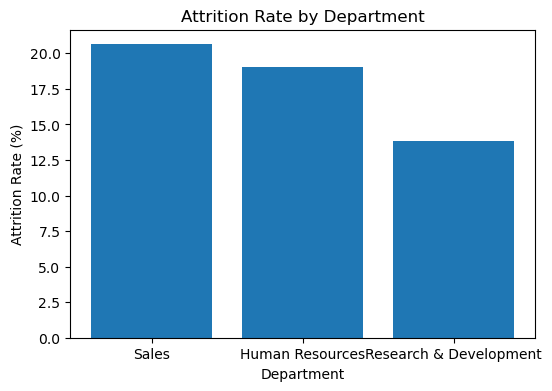

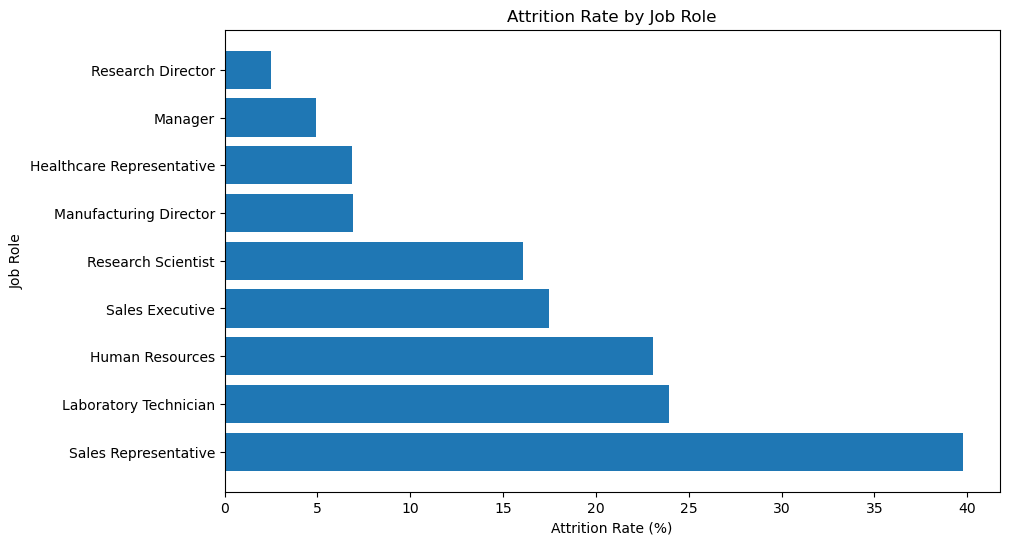

In [58]:
import matplotlib.pyplot as plt

### Bar chart showing attrition rate by Department

plt.figure(figsize=(6,4))
plt.bar( Attrition_Department.index,  Attrition_Department.values)

plt.title("Attrition Rate by Department")
plt.xlabel("Department")
plt.ylabel("Attrition Rate (%)")

plt.show()

### Bar chart showing attrition rate by Job Role

plt.figure(figsize=(10,6))

bars = plt.barh(Attrition_Jobrole.index, Attrition_Jobrole.values)

plt.title("Attrition Rate by Job Role")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("Job Role")

plt.show()

<Figure size 600x500 with 0 Axes>

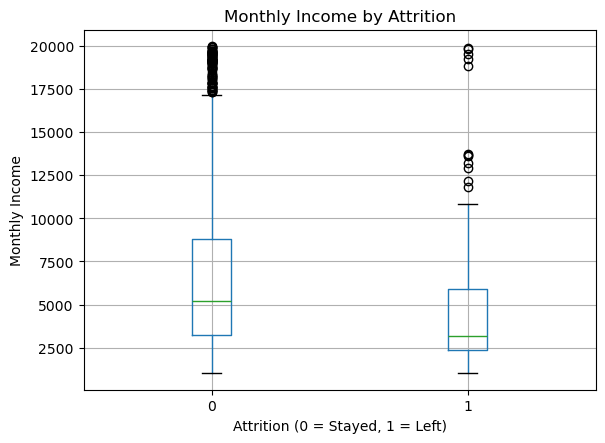

In [59]:
### Box plot comparing Monthly Income of employees who left vs stayed

plt.figure(figsize=(6,5))

df.boxplot(column="MonthlyIncome", by="Attrition")

plt.title("Monthly Income by Attrition")
plt.suptitle("")
plt.xlabel("Attrition (0 = Stayed, 1 = Left)")
plt.ylabel("Monthly Income")

plt.show()

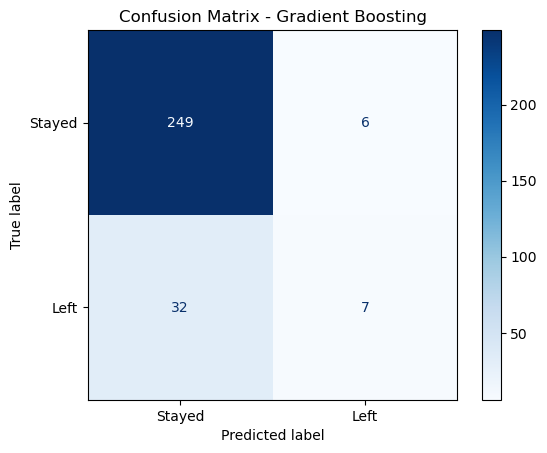

In [61]:
### Confusion Matrix heatmap for your best model

from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(y_test, gbc_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Left"]
)

disp.plot(cmap="Blues")

plt.title("Confusion Matrix - Gradient Boosting")
plt.show()

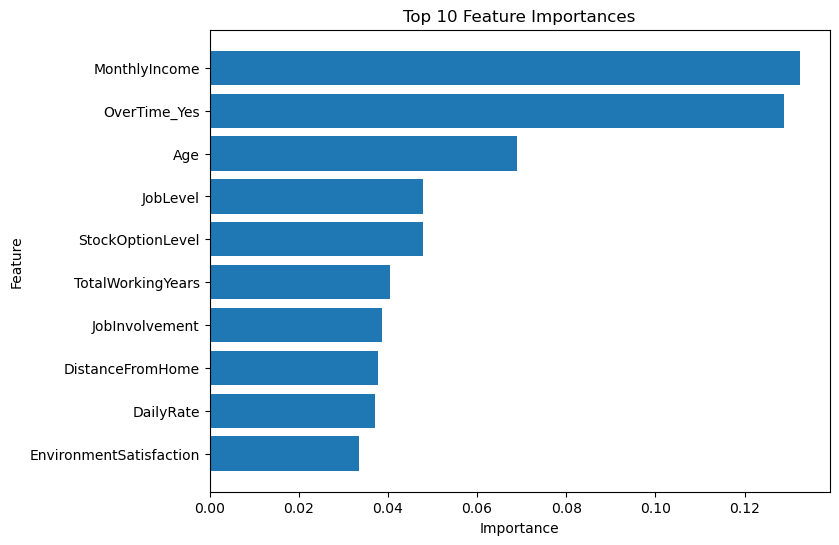

In [65]:
### Horizontal bar chart of Top 10 Feature Importances from your best model

plt.figure(figsize=(8,6))

plt.barh(top10["Feature"], top10["Importance"])

plt.title("Top 10 Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.gca().invert_yaxis()

plt.show()

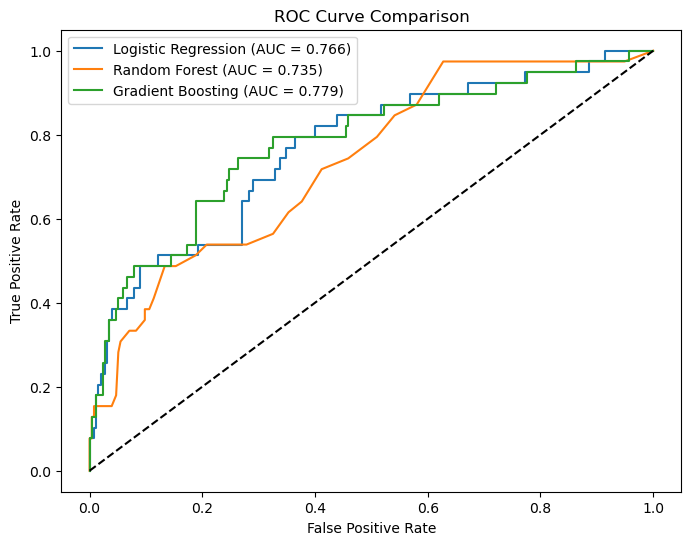

In [73]:
### ROC Curve comparing all 3 models on one graph

from sklearn.metrics import roc_curve, roc_auc_score



# ROC values
lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_prob)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)
gbc_fpr, gbc_tpr, _ = roc_curve(y_test, gbc_prob)

plt.figure(figsize=(8,6))

plt.plot(
    lr_fpr,
    lr_tpr,
    label=f"Logistic Regression (AUC = {roc_auc_score(y_test, lr_prob):.3f})"
)

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Random Forest (AUC = {roc_auc_score(y_test, rf_prob):.3f})"
)

plt.plot(
    gbc_fpr,
    gbc_tpr,
    label=f"Gradient Boosting (AUC = {roc_auc_score(y_test, gbc_prob):.3f})"
)

plt.plot([0,1],[0,1],"k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()

plt.show()

In [74]:
## HR Insights & Business Recommendations

### This project aimed to predict whether an employee is likely to leave the company using machine learning. 
### After analyzing the data, I found that work-life balance, monthly income, and years at the company are important factors that influence employee attrition. 
### Employees in the Sales department, especially Sales Representatives, showed the highest attrition rate.
### Among the three models, Gradient Boosting performed the best because it achieved the highest ROC-AUC score and provided the best overall balance of performance.
### Based on these findings, HR should focus on improving work-life balance and supporting employees in high-risk roles through regular feedback and retention programs.
### Although the model provides useful insights, it should be used along with human judgment because it cannot consider personal reasons for employees leaving the company.
